# Prevision des exportations de phosphates et derives

**Objectif** : prevoir les exportations mensuelles de "Phosphates et derives"
(Millions DH) a partir de l'historique de la serie et des importations en Admission
Temporaire (AT) de produits entrant dans la transformation/production des phosphates,
utilisees comme variables exogenes. Une correlation entre ces importations et les
exportations n'etablit pas de lien de causalite.

**Donnees** : `data_phosphates.xlsx`, 146 mois (2014-01 a 2026-02). Cible :
`Phosphates et derives` (Millions DH). 14 variables explicatives : importations AT
(DH, converties en Millions DH).

**Demarche (CRISP-DM)** : split temporel, preparation (train uniquement), 6 modeles
(Naive saisonnier, Ridge, Random Forest, XGBoost, ARIMA, SARIMAX) avec validation
temporelle homogene, evaluation sur test unique puis multi-fenetres, reentrainement
final et prevision. ARIMA (autoregressif pur, sans exogenes) et SARIMAX (avec les
memes exogenes que les modeles de regression) permettent de mesurer separement
l'apport de la modelisation classique et celui des variables exogenes.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning

from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

from xgboost import XGBRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Comprehension des donnees

In [2]:
raw = pd.read_excel("data/data_phosphates.xlsx")

col_map = {
    "TOURTEAUX ET AUTRES RÉSIDUS DES INDUSTRIES ALIMENTAIRES": "tourteaux",
    "ACIDE PHOSPHORIQUE": "acide_phosphorique",
    "ENGRAIS NATURELS ET CHIMIQUES": "engrais",
    "PRODUITS CHIMIQUES": "produits_chimiques",
    "GAZ DE PÉTROLE ET AUTRES HYDROCARBURES": "gaz_petrole",
    "HOUILLES, COKES ET COMBUSTIBLES SOLIDES SIMILAIRES": "houilles_cokes",
    "Huile brute de pétrole": "huile_brute",
    "DÉCHETS DE MATIERES TEXTILES": "dechets_textiles",
    "SOUS-PRODUITS ANIMAUX NON COMESTIBLES": "sous_produits_animaux",
    "AUTRES PRODUITS BRUTS D'ORIGINE MINÉRALE": "produits_bruts_mineraux",
    "PHOSPHATES": "phosphates_bruts",
    "Machines et appareils électriques à usages divers": "machines_electriques",
    "MACHINES ET MATÉRIEL DE GÉNIE CIVIL ET DE CONSTRUCTION": "machines_genie_civil",
    "Machines, appareils pour industries alimentaires": "machines_agroalimentaire",
    "Phosphates et derivés": "target",
}
df = raw.rename(columns=col_map)

TARGET = "target"
EXOG_RAW = [c for c in col_map.values() if c not in ("target",)]

df["DATE"] = pd.to_datetime(df["DATE"])
df = df.sort_values("DATE").reset_index(drop=True).set_index("DATE").asfreq("MS")

print(df.shape)
df.info()

(146, 15)
<class 'pandas.DataFrame'>
DatetimeIndex: 146 entries, 2014-01-01 to 2026-02-01
Freq: MS
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   tourteaux                 146 non-null    int64  
 1   acide_phosphorique        146 non-null    int64  
 2   engrais                   146 non-null    float64
 3   produits_chimiques        146 non-null    float64
 4   gaz_petrole               146 non-null    int64  
 5   houilles_cokes            146 non-null    float64
 6   huile_brute               146 non-null    int64  
 7   dechets_textiles          146 non-null    float64
 8   sous_produits_animaux     146 non-null    float64
 9   produits_bruts_mineraux   146 non-null    float64
 10  phosphates_bruts          146 non-null    int64  
 11  machines_electriques      146 non-null    float64
 12  machines_genie_civil      146 non-null    int64  
 13  machines_agroalimentaire  146 non-null

In [3]:
# Importations AT en DH -> Millions DH, pour etre homogenes avec la cible.
df[EXOG_RAW] = df[EXOG_RAW] / 1e6
df[[TARGET] + EXOG_RAW].describe().T

,count,mean,std,min,25%,50%,75%,max
target,146.0,5391.527603,2435.093656,1794.440000,3525.435000,4518.960000,6571.572500,13618.130000
tourteaux,146.0,0.195496,0.704008,0.000000,0.000000,0.000000,0.082009,4.571925
acide_phosphorique,146.0,2.603130,2.065899,0.000000,1.326245,2.122525,3.108575,12.005207
engrais,146.0,62.748387,79.857307,0.000000,0.291820,45.227212,77.154247,463.640701
produits_chimiques,146.0,217.020449,135.356890,62.243026,117.866393,173.408815,268.484853,747.002512
gaz_petrole,146.0,0.456854,2.027107,0.000000,0.000000,0.000000,0.000000,19.542798
houilles_cokes,146.0,0.211842,0.866644,0.000000,0.000000,0.048980,0.129367,9.915999
huile_brute,146.0,107.677946,345.212706,0.000000,0.000000,0.000000,0.000000,1907.308790
dechets_textiles,146.0,1.283439,0.792311,0.000000,0.757791,1.158114,1.759693,4.137921
sous_produits_animaux,146.0,57.332110,17.543023,17.783193,44.482201,56.518726,69.627423,115.938160


In [4]:
print("Valeurs manquantes :", df.isna().sum().sum())

Valeurs manquantes : 0


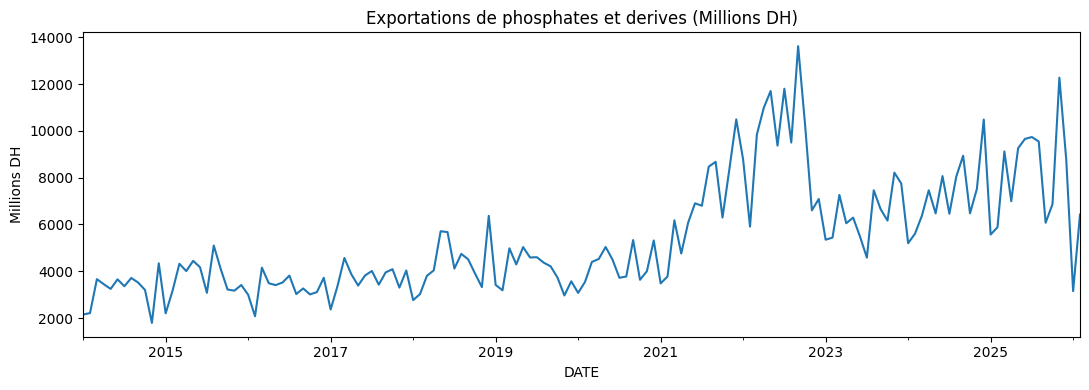

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
df[TARGET].plot(ax=ax)
ax.set_title("Exportations de phosphates et derives (Millions DH)")
ax.set_ylabel("Millions DH")
plt.tight_layout()
plt.show()

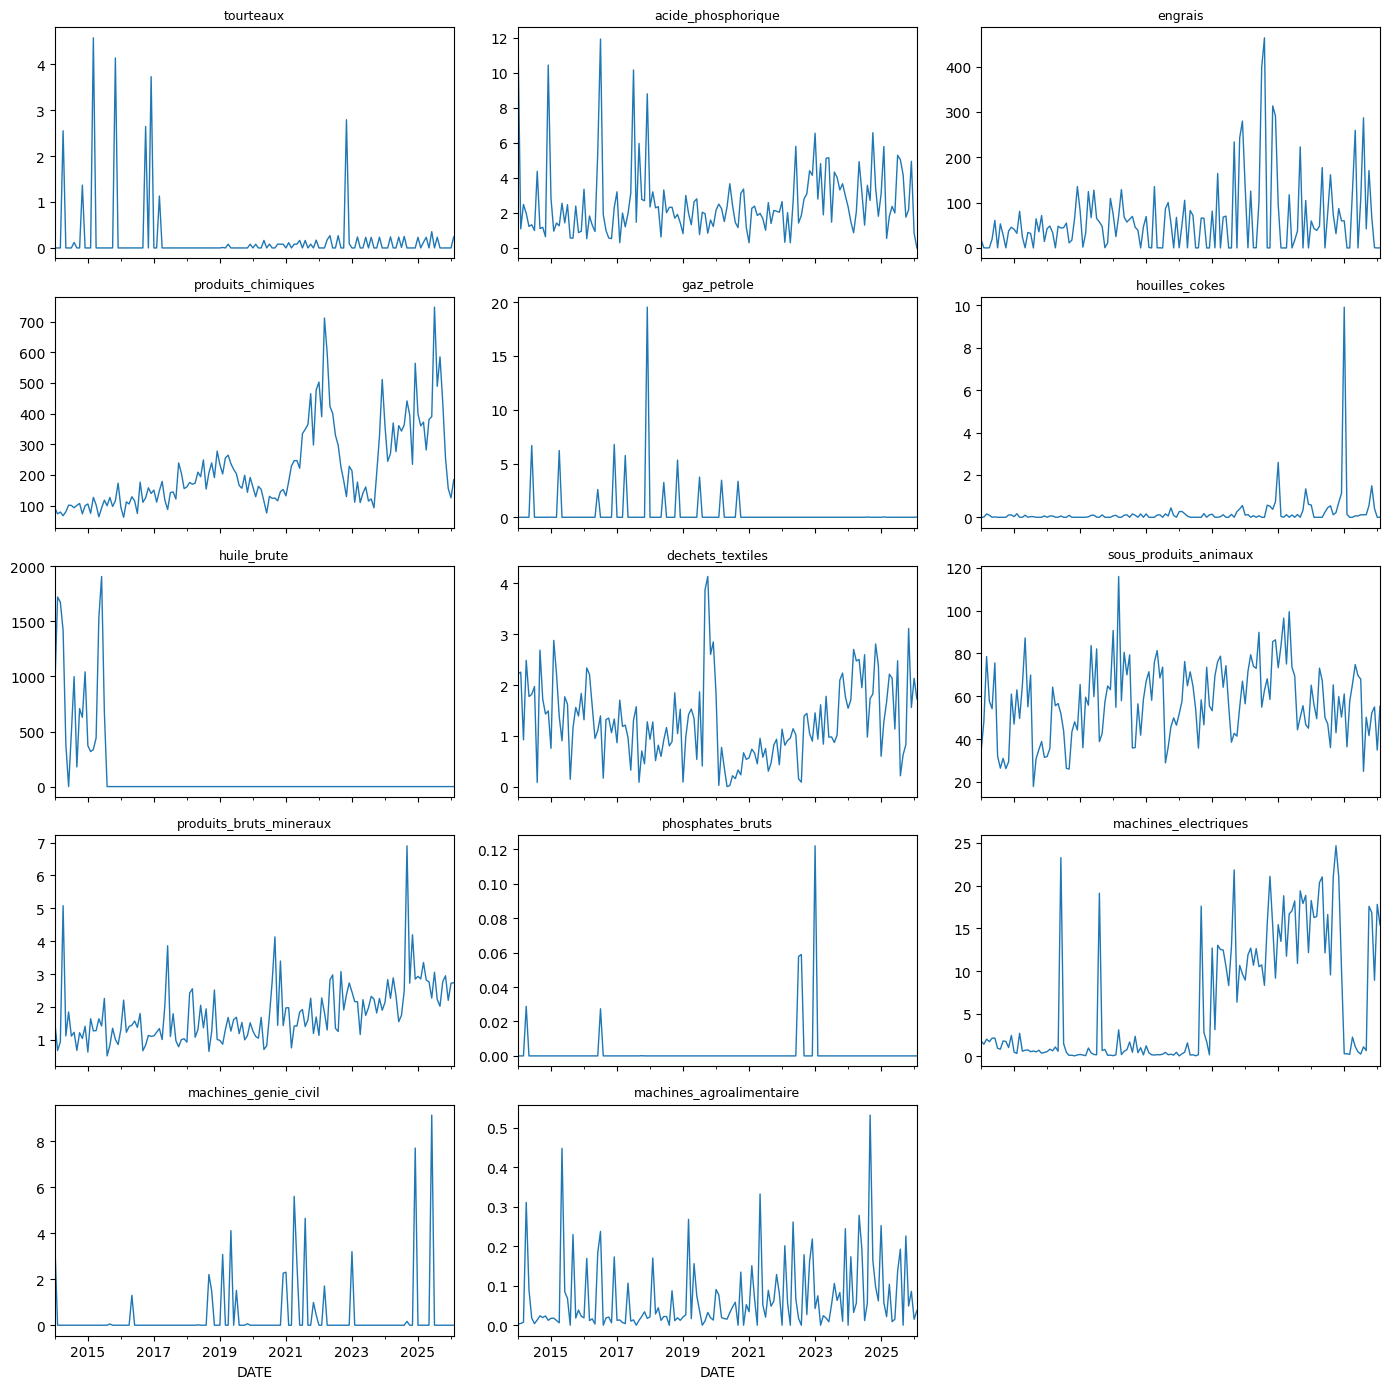

In [6]:
fig, axes = plt.subplots(5, 3, figsize=(14, 14), sharex=True)
for ax, col in zip(axes.ravel(), EXOG_RAW):
    df[col].plot(ax=ax, linewidth=1)
    ax.set_title(col, fontsize=9)
for ax in axes.ravel()[len(EXOG_RAW):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Split temporel

Split effectue avant toute analyse : stationnarite, CCF et choix des lags (section 3)
ne portent que sur le train, le test reste invisible jusqu'a l'evaluation.

In [7]:
split_idx = int(len(df) * 0.8)
split_date = df.index[split_idx]

train_raw, test_raw = df.iloc[:split_idx], df.iloc[split_idx:]
print(f"train: {train_raw.index.min().date()} -> {train_raw.index.max().date()} ({len(train_raw)} obs)")
print(f"test:  {test_raw.index.min().date()} -> {test_raw.index.max().date()} ({len(test_raw)} obs)")

train: 2014-01-01 -> 2023-08-01 (116 obs)
test:  2023-09-01 -> 2026-02-01 (30 obs)


## 3. Preparation des donnees (train uniquement)

### 3.1 Stationnarite

ADF (H0 : non stationnaire) et KPSS (H0 : stationnaire) testent des hypotheses
opposees ; les utiliser ensemble evite de conclure a tort avec un seul des deux.

In [8]:
def stationarity_tests(series, label):
    series = series.dropna()
    adf_stat, adf_p = adfuller(series, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(series, regression="c", nlags="auto")[:2]

    adf_stationary = adf_p < 0.05
    kpss_stationary = kpss_p > 0.05
    if adf_stationary and kpss_stationary:
        verdict = "stationnaire"
    elif not adf_stationary and not kpss_stationary:
        verdict = "non stationnaire"
    else:
        verdict = "incertain (ADF et KPSS en desaccord)"

    return {
        "serie": label, "adf_stat": adf_stat, "adf_pvalue": adf_p,
        "kpss_stat": kpss_stat, "kpss_pvalue": kpss_p, "verdict": verdict,
    }


stationarity_target = pd.DataFrame([
    stationarity_tests(train_raw[TARGET], "target (niveau, train)"),
    stationarity_tests(train_raw[TARGET].diff(), "target (differenciee ordre 1, train)"),
])
stationarity_target

/tmp/ipykernel_1999/1946748132.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p = adfuller(series, autolag="AIC")[:2]
/tmp/ipykernel_1999/1946748132.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(series, regression="c", nlags="auto")[:2]
/tmp/ipykernel_1999/1946748132.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will sw

,serie,adf_stat,adf_pvalue,kpss_stat,kpss_pvalue,verdict
0,"target (niveau, train)",-1.700113,4.310541e-01,1.069146,0.010000,non stationnaire
1,"target (differenciee ordre 1, train)",-12.206304,1.191416e-22,0.415804,0.070343,stationnaire


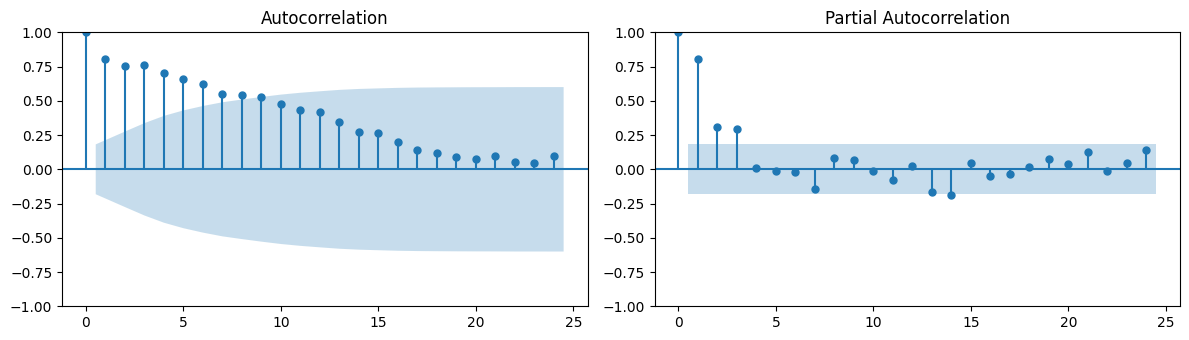

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(train_raw[TARGET].dropna(), lags=24, ax=axes[0])
plot_pacf(train_raw[TARGET].dropna(), lags=24, ax=axes[1])
plt.tight_layout()
plt.show()

### 3.2 Correlation croisee (CCF)

L'ACF ne renseigne que sur la relation de la cible avec son propre passe. Pour les
exogenes, on calcule `target_t` vs `exog_{t-k}`, sur series **differenciees** (la
cible n'est pas stationnaire au niveau — une correlation sur series brutes avec
tendance serait fallacieuse), et uniquement sur le train. Un `corr` eleve indique une
association temporelle, pas une causalite.

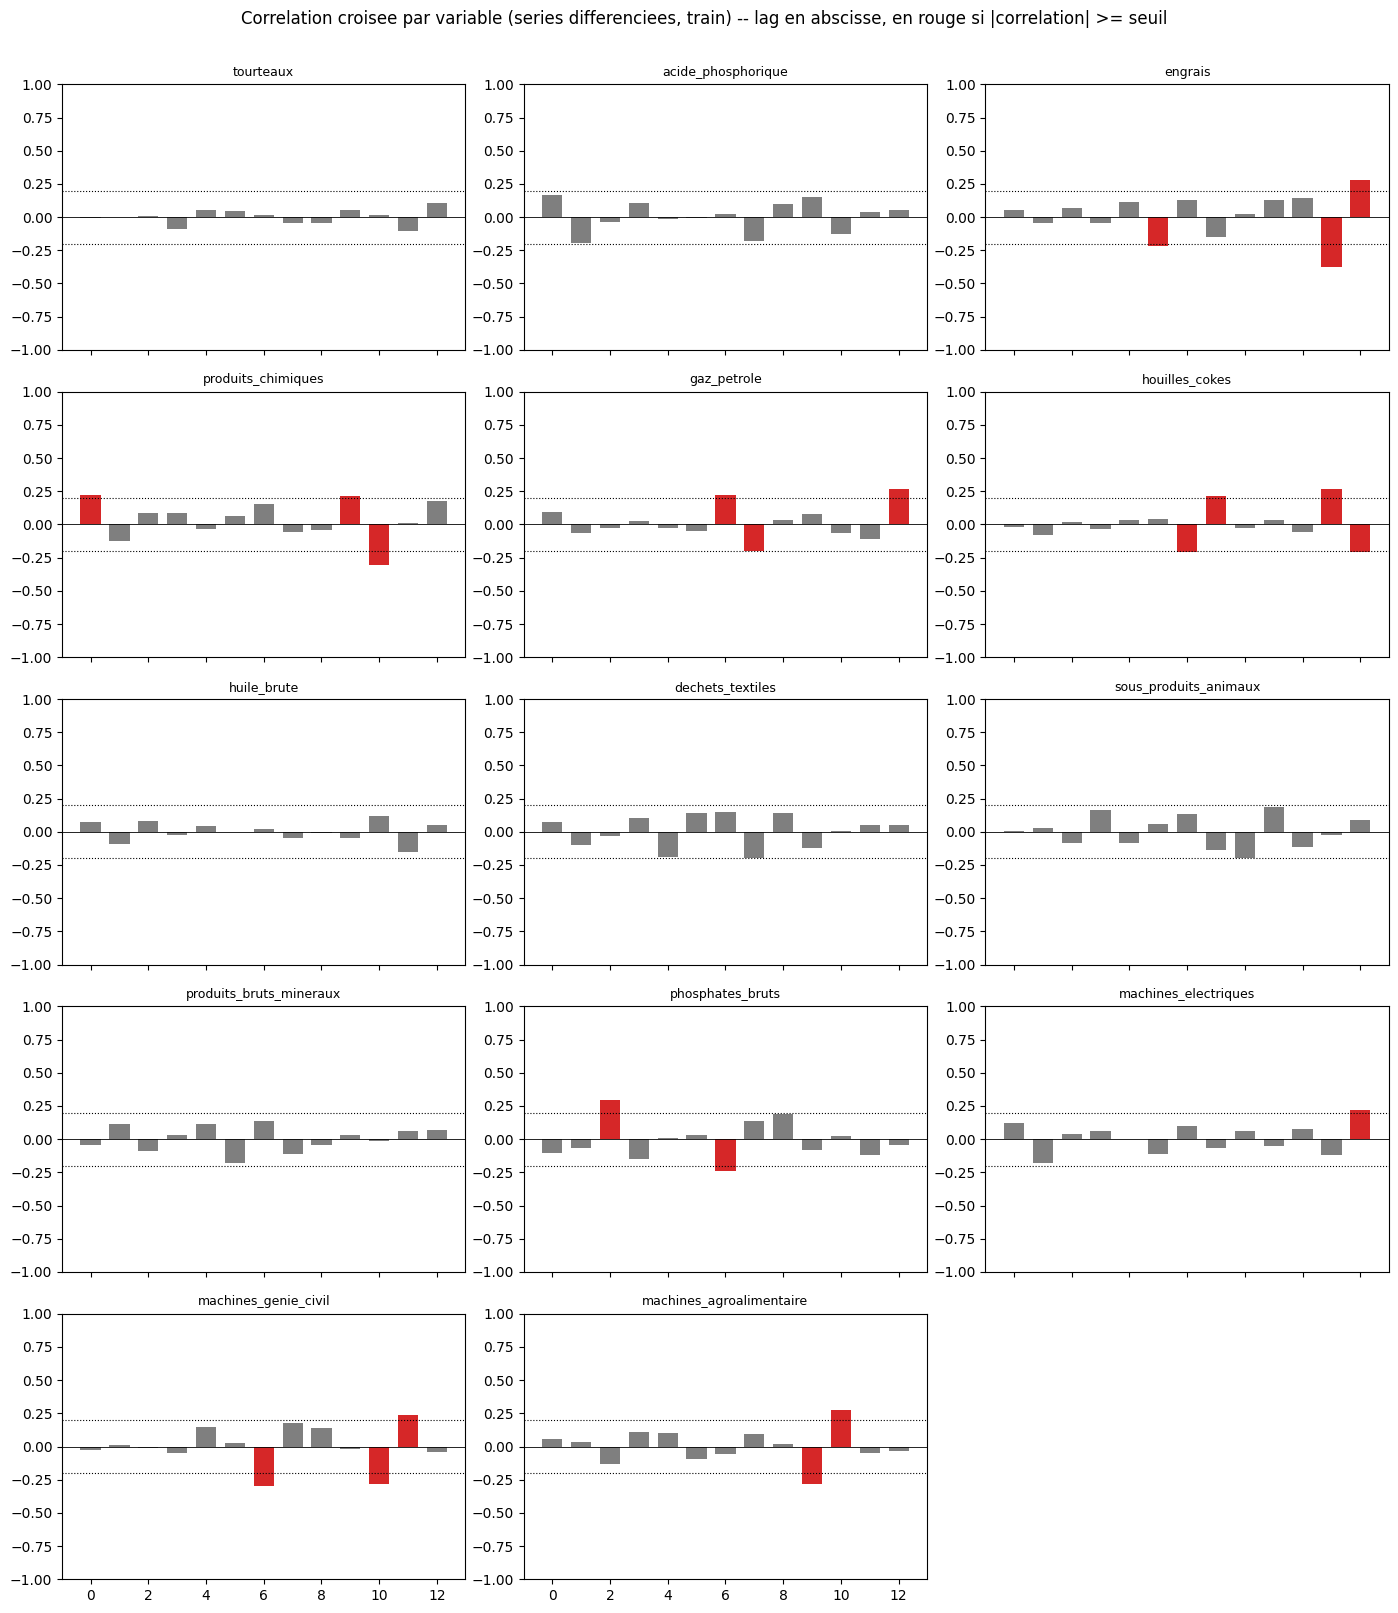

In [10]:
MAX_LAG = 12
CORR_THRESHOLD = 0.20  # seuil exploratoire (voir note ci-dessous), utilise pour la viz et la selection
train_diff = train_raw.diff().dropna()


def cross_corr(target_series, exog_series, max_lag):
    return pd.Series(
        [target_series.corr(exog_series.shift(k)) for k in range(0, max_lag + 1)],
        index=range(0, max_lag + 1),
    )


ccf_matrix = pd.DataFrame(
    {col: cross_corr(train_diff[TARGET], train_diff[col], MAX_LAG) for col in EXOG_RAW}
)

fig, axes = plt.subplots(5, 3, figsize=(14, 16), sharex=True)
for ax, col in zip(axes.ravel(), EXOG_RAW):
    colors = ["tab:red" if abs(v) >= CORR_THRESHOLD else "tab:gray" for v in ccf_matrix[col]]
    ax.bar(ccf_matrix.index, ccf_matrix[col], color=colors, width=0.7)
    ax.axhline(CORR_THRESHOLD, color="black", linestyle=":", linewidth=0.8)
    ax.axhline(-CORR_THRESHOLD, color="black", linestyle=":", linewidth=0.8)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_ylim(-1, 1)
    ax.set_title(col, fontsize=9)
for ax in axes.ravel()[len(EXOG_RAW):]:
    ax.axis("off")
fig.suptitle("Correlation croisee par variable (series differenciees, train) -- lag en abscisse, "
             "en rouge si |correlation| >= seuil", y=1.005)
plt.tight_layout()
plt.show()


Seuil 0,20 : critere exploratoire, pas un test de significativite. Un seul lag
(le plus correle) est retenu par variable — simplification assumee, pas bloquante.

In [11]:
selected_lags = {}
for col in EXOG_RAW:
    corr_by_lag = ccf_matrix[col].drop(index=0)  # lag 0 exclu : non disponible en prevision
    best_lag = corr_by_lag.abs().idxmax()
    best_corr = corr_by_lag.loc[best_lag]
    if abs(best_corr) >= CORR_THRESHOLD:
        selected_lags[col] = int(best_lag)

pd.DataFrame(
    [{"variable": k, "lag_retenu": v, "correlation": ccf_matrix.loc[v, k]} for k, v in selected_lags.items()]
).sort_values("correlation", key=abs, ascending=False)

,variable,lag_retenu,correlation
0,engrais,11,-0.374143
1,produits_chimiques,10,-0.303003
6,machines_genie_civil,6,-0.296464
4,phosphates_bruts,2,0.292847
7,machines_agroalimentaire,9,-0.284565
3,houilles_cokes,11,0.270470
2,gaz_petrole,12,0.268916
5,machines_electriques,12,0.222165


Verification : le lag est choisi sur la serie differenciee (evite une correlation
artificielle due a la tendance commune aux deux series), mais applique ensuite sur
les valeurs de niveau (`df[col].shift(lag)`), car c'est la valeur brute -- pas sa
variation -- qui est disponible pour construire une feature de prevision. Le lag
exprime un decalage temporel, pas un changement d'echelle. On verifie ci-dessous si
le meme lag aurait ete retenu en travaillant directement sur les niveaux.


In [12]:
ccf_matrix_level = pd.DataFrame(
    {col: cross_corr(train_raw[TARGET], train_raw[col], MAX_LAG) for col in EXOG_RAW}
)

selected_lags_level = {}
for col in EXOG_RAW:
    corr_by_lag = ccf_matrix_level[col].drop(index=0)
    best_lag = corr_by_lag.abs().idxmax()
    if abs(corr_by_lag.loc[best_lag]) >= CORR_THRESHOLD:
        selected_lags_level[col] = int(best_lag)

agree = sum(selected_lags.get(c) == selected_lags_level.get(c) for c in EXOG_RAW)
print(f"Lag identique (niveau vs differencie) pour {agree}/{len(EXOG_RAW)} variables")
pd.DataFrame({"lag_differencie": pd.Series(selected_lags), "lag_niveau": pd.Series(selected_lags_level)})


Lag identique (niveau vs differencie) pour 4/14 variables


,lag_differencie,lag_niveau
dechets_textiles,NaN,12.0
engrais,11.0,2.0
gaz_petrole,12.0,NaN
houilles_cokes,11.0,8.0
huile_brute,NaN,9.0
machines_agroalimentaire,9.0,3.0
machines_electriques,12.0,12.0
machines_genie_civil,6.0,11.0
phosphates_bruts,2.0,2.0
produits_bruts_mineraux,NaN,1.0


### 3.3 Feature engineering

Lags de la cible choisis parmi les plus correles a l'ACF (serie differenciee, comme pour la
CCF), pas arbitrairement fixes -- voir cellule suivante. Lags des exogenes decides sur le
train (section 3.2), appliques ensuite a toute la serie (`exog.shift(lag)`, uniquement des
valeurs passees, aucune fuite). Fenetres glissantes (`ROLL_WINDOWS`) gardees a 3/6/12 mois :
ce sont des periodes de lissage standard (trimestre/semestre/annee), pas des lags a proprement
parler, donc pas de selection par correlation ici -- 12 correspond aussi a une saisonnalite annuelle
plausible, mais faible sur ce jeu de donnees (ACF au lag 12 d'environ 0,21 sur la serie differenciee).


In [13]:
N_TARGET_LAGS = 5  # meme nombre que l'ancien choix fixe [1, 2, 3, 6, 12] : dimensionnalite inchangee

acf_vals, acf_confint = acf(train_diff[TARGET], nlags=MAX_LAG, alpha=0.05)
acf_by_lag = pd.Series(acf_vals[1:], index=range(1, MAX_LAG + 1))

LAG_TARGET = sorted(acf_by_lag.abs().sort_values(ascending=False).index[:N_TARGET_LAGS].tolist())
ROLL_WINDOWS = [3, 6, 12]

print("ACF par lag (serie differenciee, train) :")
print(acf_by_lag.round(3).to_dict())
print("LAG_TARGET retenu (top-5 |ACF|) :", LAG_TARGET)


ACF par lag (serie differenciee, train) :
{1: -0.365, 2: -0.145, 3: 0.163, 4: -0.033, 5: -0.047, 6: 0.14, 7: -0.186, 8: -0.005, 9: 0.106, 10: -0.083, 11: -0.111, 12: 0.207}
LAG_TARGET retenu (top-5 |ACF|) : [1, 2, 3, 7, 12]


/tmp/ipykernel_1999/132913804.py:3: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_vals, acf_confint = acf(train_diff[TARGET], nlags=MAX_LAG, alpha=0.05)


In [14]:
features = pd.DataFrame(index=df.index)
features[TARGET] = df[TARGET]

for k in LAG_TARGET:
    features[f"target_lag{k}"] = df[TARGET].shift(k)

for w in ROLL_WINDOWS:
    features[f"target_roll_mean{w}"] = df[TARGET].shift(1).rolling(w).mean()
    features[f"target_roll_std{w}"] = df[TARGET].shift(1).rolling(w).std()

for col, lag in selected_lags.items():
    features[f"{col}_lag{lag}"] = df[col].shift(lag)

features["month_sin"] = np.sin(2 * np.pi * df.index.month / 12)
features["month_cos"] = np.cos(2 * np.pi * df.index.month / 12)

features = features.dropna()
FEATURE_COLS = [c for c in features.columns if c != TARGET]
print(features.shape)
features.head()

(134, 22)


,target,target_lag1,target_lag2,target_lag3,target_lag7,target_lag12,target_roll_mean3,target_roll_std3,target_roll_mean6,target_roll_std6,...,engrais_lag11,produits_chimiques_lag10,gaz_petrole_lag12,houilles_cokes_lag11,phosphates_bruts_lag2,machines_electriques_lag12,machines_genie_civil_lag6,machines_agroalimentaire_lag9,month_sin,month_cos
DATE,,,,,,,,,,,,,,,,,,,,,
2015-01-01,2202.67,4340.43,1794.44,3201.24,3655.51,2151.22,3112.036667,1275.336895,3321.061667,845.900218,...,0.292146,79.415023,0.0,0.007402,0.0,1.796574,0.0,0.310919,0.500000,8.660254e-01
2015-02-01,3164.48,2202.67,4340.43,1794.44,3360.21,2213.76,2779.180000,1367.402320,3128.138333,959.550598,...,0.000000,67.245515,0.0,0.154786,0.0,1.423508,0.0,0.089871,0.866025,5.000000e-01
2015-03-01,4319.53,3164.48,2202.67,4340.43,3713.34,3662.44,3235.860000,1070.666046,3036.661667,917.860403,...,0.290456,80.093067,0.0,0.099010,0.0,2.017106,0.0,0.018105,1.000000,6.123234e-17
2015-04-01,4007.82,4319.53,3164.48,2202.67,3516.71,3446.28,3228.893333,1059.898992,3170.465000,1050.735301,...,19.649722,101.601585,0.0,0.000000,0.0,1.722763,0.0,0.003998,0.866025,-5.000000e-01
2015-05-01,4444.88,4007.82,4319.53,3164.48,3201.24,3245.64,3830.610000,597.568125,3304.895000,1105.623001,...,60.819875,100.847183,0.0,0.016120,0.0,2.132972,0.0,0.013250,0.500000,-8.660254e-01


In [15]:
train, test = features[features.index < split_date], features[features.index >= split_date]
X_train, y_train = train[FEATURE_COLS], train[TARGET]
X_test, y_test = test[FEATURE_COLS], test[TARGET]

print(f"train: {train.index.min().date()} -> {train.index.max().date()} ({len(train)} obs)")
print(f"test:  {test.index.min().date()} -> {test.index.max().date()} ({len(test)} obs)")

train: 2015-01-01 -> 2023-08-01 (104 obs)
test:  2023-09-01 -> 2026-02-01 (30 obs)


## 4. Modelisation

Baseline : naif saisonnier (`y_t = y_{t-12}`), choisi pour tenir compte d'une
eventuelle saisonnalite annuelle. Validation : `TimeSeriesSplit` (5 plis, expanding) + `GridSearchCV`
pour Ridge/Random Forest/XGBoost -- meme methode, comparaison homogene. Ridge (sensible
a l'echelle) passe par un `Pipeline` ajuste par pli. ARIMA et SARIMAX suivent une
demarche differente, propre aux modeles de series chronologiques classiques : ordre
choisi par AIC sur le train (section 4.1), puis prevision pas-a-pas sur le test.


In [16]:
predictions = {
    "Naive saisonnier": df[TARGET].shift(12).reindex(test.index).values,
}

TSCV = TimeSeriesSplit(n_splits=5)


def grid_search(estimator, param_grid, X, y):
    search = GridSearchCV(estimator, param_grid, cv=TSCV, scoring="neg_mean_squared_error")
    search.fit(X, y)
    return search

In [17]:
model_configs = {
    "Ridge": (
        Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(random_state=RANDOM_STATE))]),
        [{"ridge__alpha": [a]} for a in np.logspace(-2, 3, 15)],
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        [
            {"n_estimators": [200], "max_depth": [4], "min_samples_leaf": [2]},
            {"n_estimators": [300], "max_depth": [6], "min_samples_leaf": [2]},
            {"n_estimators": [400], "max_depth": [8], "min_samples_leaf": [3]},
        ],
    ),
    "XGBoost": (
        XGBRegressor(random_state=RANDOM_STATE, subsample=0.8, colsample_bytree=0.8),
        [
            {"n_estimators": [200], "max_depth": [2], "learning_rate": [0.05]},
            {"n_estimators": [300], "max_depth": [3], "learning_rate": [0.05]},
            {"n_estimators": [300], "max_depth": [3], "learning_rate": [0.1]},
        ],
    ),
}

fitted_models = {}
for name, (estimator, grid) in model_configs.items():
    search = grid_search(estimator, grid, X_train, y_train)
    fitted_models[name] = search.best_estimator_
    predictions[name] = search.best_estimator_.predict(X_test)
    print(f"{name} - parametres retenus :", search.best_params_)


Ridge - parametres retenus : {'ridge__alpha': np.float64(193.06977288832496)}


Random Forest - parametres retenus : {'max_depth': 6, 'min_samples_leaf': 2, 'n_estimators': 300}


XGBoost - parametres retenus : {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}


### 4.1 ARIMA (autoregressif pur) et SARIMAX (avec exogenes)

`ARIMA` ne modelise que la dynamique propre de la cible ; `SARIMAX` ajoute les memes
exogenes que les modeles ML (standardisees, train uniquement), pour mesurer leur apport.

Ordre `(p, d, q)(P, D, Q, s)` choisi par grille AIC restreinte (train limite a 116 mois, 104 apres construction des lags) ;
`maxiter=200` et priorite aux ordres convergents evitent un AIC peu fiable.

Evaluation pas a pas (`append(obs_reelle, refit=False)`), meme logique walk-forward
que les modeles ML : aucune fuite, aucun reentrainement pendant le test.


In [18]:
ARIMA_ORDERS = [(1, 1, 0), (2, 1, 0), (1, 1, 1), (2, 1, 1), (0, 1, 2), (3, 1, 0), (1, 1, 2)]
SARIMAX_ORDERS = [(1, 1, 0), (1, 1, 1), (2, 1, 1), (2, 1, 0)]
SARIMAX_SEASONAL = [(0, 1, 1, 12), (1, 1, 0, 12), (1, 1, 1, 12)]

EXOG_FEATURE_COLS = [f"{col}_lag{lag}" for col, lag in selected_lags.items()]
exog_mean, exog_std = train[EXOG_FEATURE_COLS].mean(), train[EXOG_FEATURE_COLS].std()
train_exog_s = (train[EXOG_FEATURE_COLS] - exog_mean) / exog_std
test_exog_s = (test[EXOG_FEATURE_COLS] - exog_mean) / exog_std


def fit_quiet(mod, use_sarimax, maxiter=200):
    # maxiter releve (defaut statsmodels : 50) + detection de la convergence,
    # sans laisser les ConvergenceWarning s'imprimer en boucle.
    # NB : ARIMA est en interne une sous-classe de SARIMAX (isinstance ne suffit
    # pas a les distinguer), d'ou le flag explicite use_sarimax.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        if use_sarimax:
            res = mod.fit(disp=False, maxiter=maxiter)
        else:
            res = mod.fit(method_kwargs={"maxiter": maxiter})
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return res, converged


def select_order_aic(endog, exog, orders, seasonal_orders=None, use_sarimax=False, maxiter=200):
    # A AIC proche, on privilegie un ordre qui converge.
    best_converged, best_any = None, None
    for order in orders:
        for sorder in (seasonal_orders or [(0, 0, 0, 0)]):
            try:
                mod = (SARIMAX(endog, exog=exog, order=order, seasonal_order=sorder,
                               enforce_stationarity=False, enforce_invertibility=False)
                       if use_sarimax else ARIMA(endog, order=order))
                res, converged = fit_quiet(mod, use_sarimax, maxiter=maxiter)
                candidate = (res.aic, order, sorder, converged)
                if best_any is None or candidate[0] < best_any[0]:
                    best_any = candidate
                if converged and (best_converged is None or candidate[0] < best_converged[0]):
                    best_converged = candidate
            except Exception:
                continue
    return best_converged if best_converged is not None else best_any


def rolling_one_step(endog_train, endog_test, order, seasonal_order=None,
                      exog_train=None, exog_test=None, use_sarimax=False, maxiter=200):
    mod = (SARIMAX(endog_train, exog=exog_train, order=order, seasonal_order=seasonal_order,
                   enforce_stationarity=False, enforce_invertibility=False)
           if use_sarimax else ARIMA(endog_train, order=order))
    res, _ = fit_quiet(mod, use_sarimax, maxiter=maxiter)
    preds = []
    for i in range(len(endog_test)):
        step_exog = exog_test.iloc[[i]] if use_sarimax else None
        preds.append(res.get_forecast(steps=1, exog=step_exog).predicted_mean.iloc[0])
        res = res.append(endog_test.iloc[[i]], exog=step_exog, refit=False)
    return np.array(preds)


_, arima_order, _, arima_converged = select_order_aic(train[TARGET], None, ARIMA_ORDERS)
predictions["ARIMA"] = rolling_one_step(train[TARGET], test[TARGET], order=arima_order)
print(f"ARIMA - ordre retenu : {arima_order} "
      f"(convergence : {'ok' if arima_converged else 'non atteinte, meilleur candidat garde quand meme'})")

_, sarimax_order, sarimax_seasonal, sarimax_converged = select_order_aic(
    train[TARGET], train_exog_s, SARIMAX_ORDERS, SARIMAX_SEASONAL, use_sarimax=True
)
predictions["SARIMAX"] = rolling_one_step(
    train[TARGET], test[TARGET], order=sarimax_order, seasonal_order=sarimax_seasonal,
    exog_train=train_exog_s, exog_test=test_exog_s, use_sarimax=True,
)
print(f"SARIMAX - ordre retenu : {sarimax_order} {sarimax_seasonal} "
      f"(convergence : {'ok' if sarimax_converged else 'non atteinte, meilleur candidat garde quand meme'})")


ARIMA - ordre retenu : (2, 1, 0) (convergence : ok)


SARIMAX - ordre retenu : (2, 1, 1) (1, 1, 1, 12) (convergence : ok)


## 5. Evaluation

### 5.1 Test unique (dernier 20%)

In [19]:
def evaluate(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2": r2_score(y_true, y_pred),
    }


results = pd.DataFrame({name: evaluate(y_test, pred) for name, pred in predictions.items()}).T
results = results.sort_values("RMSE")
results

,RMSE,MAE,MAPE,R2
ARIMA,1953.219047,1435.321692,22.416974,-0.132603
Random Forest,2032.552144,1508.460123,25.204517,-0.226476
XGBoost,2115.684511,1599.640037,26.616409,-0.328855
Ridge,2141.102939,1654.144369,23.668670,-0.360977
Naive saisonnier,2356.629647,1764.326333,23.858079,-0.648763
SARIMAX,3141.281458,2459.552699,35.337334,-1.929472


**R² negatif pour tous les modeles.** Sur le test unique (5.1), les 6 modeles affichent un R²
negatif -- de -0.13 (ARIMA, le moins mauvais) a -1.93 (SARIMAX, le pire). Un R² negatif signifie
qu'aucun modele ne fait mieux, sur cette periode, qu'une prevision constante egale a la moyenne
des valeurs reelles du test. Cette moyenne n'est pas connue au moment de prevoir : la depasser
n'a rien d'evident pour une serie mensuelle aussi bruitee, et un R² negatif est frequent en
prevision hors echantillon.

Explication chiffree : le R² compare l'erreur du modele a la variabilite propre de la periode test.
Or le test varie relativement peu (ecart-type d'environ 1 870 M DH, contre environ 2 330 M DH
sur les 30 derniers mois du train), alors que le RMSE d'ARIMA (1 953 M DH) depasse cet ecart-type :
le R² devient donc mecaniquement negatif. Il ne s'agit pas d'un changement de niveau au moment du
split (moyenne du test d'environ 7 510 M DH, proche de celle de la fin du train, environ 7 880 M DH) :
la rupture principale de la serie se situe en 2022, dans le train. D'ou l'interet de la section 5.2,
qui evalue les modeles sur plusieurs periodes plutot que sur une seule.

In [20]:
model_names = list(model_configs.keys()) + ["ARIMA", "SARIMAX"]
top2 = results.loc[model_names].sort_values("RMSE").index[:2].tolist()
best_model_name = top2[0]
print("Top 2 modeles (RMSE test) :", top2)

naive_rmse = results.loc["Naive saisonnier", "RMSE"]
beats_baseline = results.loc[model_names][results.loc[model_names, "RMSE"] < naive_rmse]
print(f"RMSE baseline (naive saisonnier) : {naive_rmse:.0f}")
print("Modeles qui font mieux que la baseline :", ", ".join(beats_baseline.index) if len(beats_baseline) else "aucun")

Top 2 modeles (RMSE test) : ['ARIMA', 'Random Forest']
RMSE baseline (naive saisonnier) : 2357
Modeles qui font mieux que la baseline : Ridge, Random Forest, XGBoost, ARIMA


SARIMAX (RMSE 3141, pire modele) est vraisemblablement sur-parametre : ordre + saisonnalite +
8 exogenes pour seulement 116 mois de train, un ratio parametres/observations defavorable qui
favorise le sur-ajustement plutot que la generalisation.

Figures de prediction limitees aux 2 meilleurs modeles.


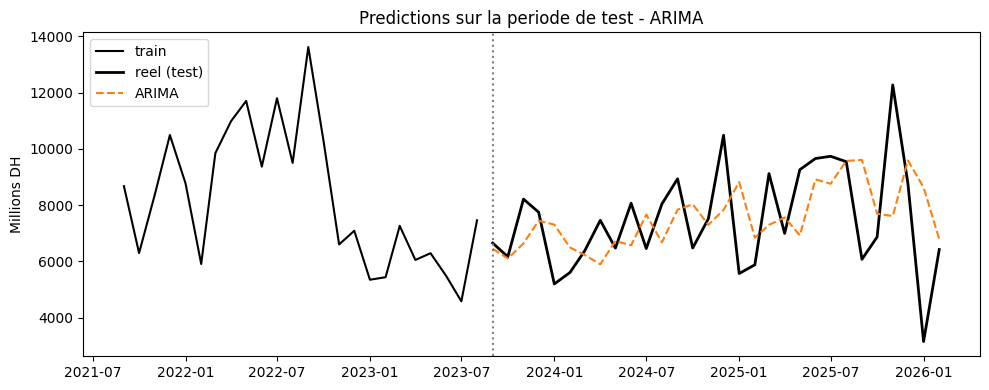

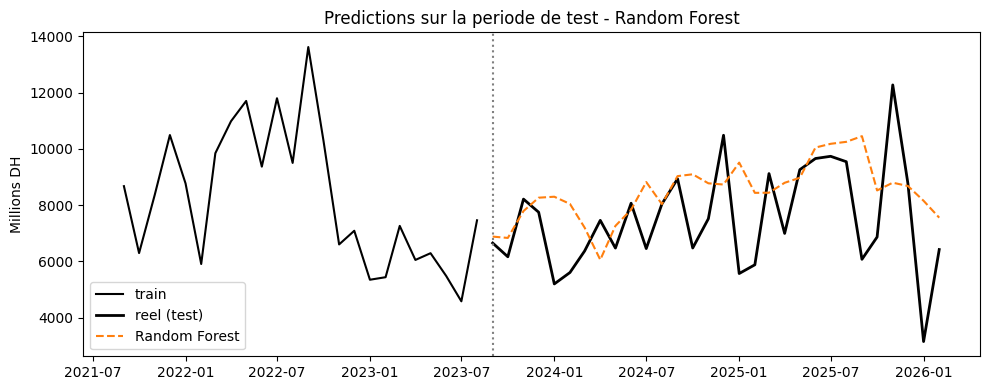

In [21]:
for name in top2:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(train.index[-24:], train[TARGET].iloc[-24:], label="train", color="black")
    ax.plot(test.index, y_test, label="reel (test)", color="black", linewidth=2)
    ax.plot(test.index, predictions[name], label=name, linestyle="--", color="tab:orange")
    ax.axvline(test.index[0], color="gray", linestyle=":")
    ax.set_title(f"Predictions sur la periode de test - {name}")
    ax.set_ylabel("Millions DH")
    ax.legend()
    plt.tight_layout()
    plt.show()

### Comparaison : features en niveau vs en variation (differenciees)

Piste suggeree par l'encadrant : tester une transformation des inputs ML. Meme feature
engineering, mais appliquee a la cible et aux exogenes differenciees (`diff()`) plutot
qu'au niveau -- Ridge/RF/XGBoost predisent alors une variation mensuelle, reconstituee en
niveau via la derniere valeur reelle connue (meme logique que le pas-a-pas d'ARIMA/SARIMAX).


In [22]:
target_diff = df[TARGET].diff()

features_diff = pd.DataFrame(index=df.index)
features_diff["target_diff"] = target_diff
for k in LAG_TARGET:
    features_diff[f"target_diff_lag{k}"] = target_diff.shift(k)
for w in ROLL_WINDOWS:
    features_diff[f"target_diff_roll_mean{w}"] = target_diff.shift(1).rolling(w).mean()
for col, lag in selected_lags.items():
    features_diff[f"{col}_diff_lag{lag}"] = df[col].diff().shift(lag)
features_diff["month_sin"] = np.sin(2 * np.pi * df.index.month / 12)
features_diff["month_cos"] = np.cos(2 * np.pi * df.index.month / 12)
features_diff = features_diff.dropna()

diff_feature_cols = [c for c in features_diff.columns if c != "target_diff"]
train_d = features_diff[features_diff.index < split_date]
test_d = features_diff[features_diff.index >= split_date]
X_train_d, y_train_d = train_d[diff_feature_cols], train_d["target_diff"]
X_test_d, y_test_d = test_d[diff_feature_cols], test_d["target_diff"]

y_prev_true = df[TARGET].shift(1).reindex(test_d.index)  # vraie valeur en t-1, pour reconstruire le niveau

predictions_diff_level = {}
for name in ["Ridge", "Random Forest", "XGBoost"]:
    estimator, grid = model_configs[name]
    search = grid_search(estimator, grid, X_train_d, y_train_d)
    diff_pred = search.best_estimator_.predict(X_test_d)
    predictions_diff_level[name] = y_prev_true.values + diff_pred

y_test_d_level = df[TARGET].reindex(test_d.index)
results_diff = pd.DataFrame(
    {name: evaluate(y_test_d_level, pred) for name, pred in predictions_diff_level.items()}
).T.sort_values("RMSE")

comparison = pd.concat(
    [results.loc[["Ridge", "Random Forest", "XGBoost"], "RMSE"].rename("RMSE_niveau"),
     results_diff["RMSE"].rename("RMSE_differencie")],
    axis=1,
)
comparison["ecart_%"] = (comparison["RMSE_differencie"] / comparison["RMSE_niveau"] - 1) * 100
comparison


,RMSE_niveau,RMSE_differencie,ecart_%
Ridge,2141.102939,2506.884791,17.083805
Random Forest,2032.552144,2081.923831,2.429049
XGBoost,2115.684511,2055.897682,-2.825886


Resultat : pas de gain net ici -- la differenciation degrade Ridge (+17%) et legerement
Random Forest (+2%), n'ameliore que marginalement XGBoost (-3%). Les features en niveau
(section 4) restent donc le choix retenu pour la suite ; cette comparaison confirme ce
choix plutot que de le remettre en cause.


Ce test unique tombe, par construction, sur une seule periode (2023-09 a
2026-02). Si cette periode contient une rupture, le R² qu'on en tire est un artefact
du decoupage, pas necessairement un jugement fiable sur le modele — d'ou la section
5.2.

### 5.2 Evaluation multi-fenetres

`TimeSeriesSplit` (expanding window, fenetres de test de 12 mois) sur l'ensemble de la
serie, pour les 2 meilleurs modeles : memes hyperparametres (deja regles en 4),
reentraines sur le train de chaque fenetre et evalues sur son test. Objectif : voir
comment R²/RMSE varient selon la periode couverte, plutot que de se fier a un seul
chiffre issu d'un seul decoupage.

In [23]:
X_all, y_all = features[FEATURE_COLS], features[TARGET]
mw_cv = TimeSeriesSplit(n_splits=7, test_size=12)

mw_rows = []
for name in top2:
    for fold, (tr_idx, te_idx) in enumerate(mw_cv.split(X_all), start=1):
        X_tr, y_tr = X_all.iloc[tr_idx], y_all.iloc[tr_idx]
        X_te, y_te = X_all.iloc[te_idx], y_all.iloc[te_idx]
        if name in fitted_models:
            model = clone(fitted_models[name])
            model.fit(X_tr, y_tr)
            pred = model.predict(X_te)
        elif name == "ARIMA":
            pred = rolling_one_step(y_tr, y_te, order=arima_order)
        else:  # SARIMAX
            mu, sd = X_tr[EXOG_FEATURE_COLS].mean(), X_tr[EXOG_FEATURE_COLS].std()
            pred = rolling_one_step(
                y_tr, y_te, order=sarimax_order, seasonal_order=sarimax_seasonal,
                exog_train=(X_tr[EXOG_FEATURE_COLS] - mu) / sd, exog_test=(X_te[EXOG_FEATURE_COLS] - mu) / sd,
                use_sarimax=True,
            )
        mw_rows.append({
            "modele": name, "fold": fold,
            "debut_test": X_te.index[0].date(), "fin_test": X_te.index[-1].date(),
            "RMSE": np.sqrt(mean_squared_error(y_te, pred)), "R2": r2_score(y_te, pred),
        })

mw_results = pd.DataFrame(mw_rows)
mw_results


,modele,fold,debut_test,fin_test,RMSE,R2
0,ARIMA,1,2019-03-01,2020-02-01,572.177476,0.260593
1,ARIMA,2,2020-03-01,2021-02-01,788.904980,-0.546672
2,ARIMA,3,2021-03-01,2022-02-01,1559.634417,0.004079
3,ARIMA,4,2022-03-01,2023-02-01,2608.181462,-0.053133
4,ARIMA,5,2023-03-01,2024-02-01,1209.691681,-0.305441
5,ARIMA,6,2024-03-01,2025-02-01,1578.798180,-0.361263
6,ARIMA,7,2025-03-01,2026-02-01,2431.938983,-0.153256
7,Random Forest,1,2019-03-01,2020-02-01,622.832960,0.123877
8,Random Forest,2,2020-03-01,2021-02-01,747.505421,-0.388601
9,Random Forest,3,2021-03-01,2022-02-01,3093.672800,-2.918575


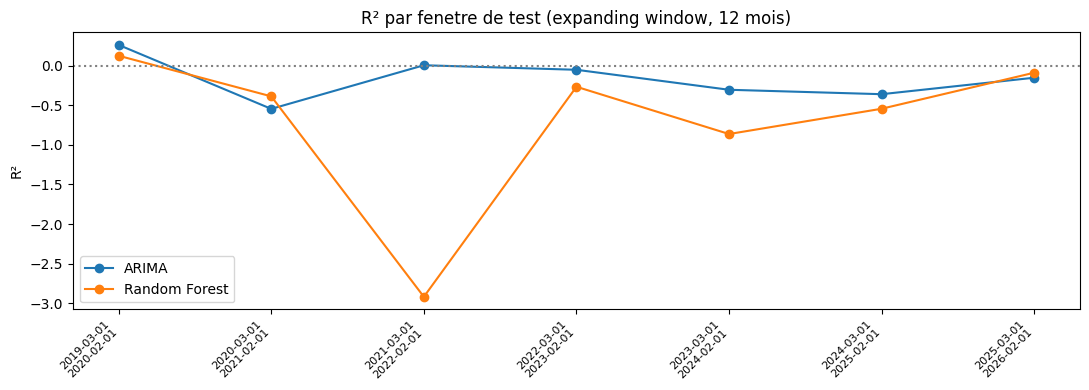

In [24]:
fig, ax = plt.subplots(figsize=(11, 4))
for name in top2:
    sub = mw_results[mw_results["modele"] == name]
    labels = [f"{d1}\n{d2}" for d1, d2 in zip(sub["debut_test"], sub["fin_test"])]
    ax.plot(labels, sub["R2"], marker="o", label=name)
ax.axhline(0, color="gray", linestyle=":")
ax.set_ylabel("R²")
ax.set_title("R² par fenetre de test (expanding window, 12 mois)")
ax.legend()
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

In [25]:
worst = mw_results.loc[mw_results["R2"].idxmin()]
best = mw_results.loc[mw_results["R2"].idxmax()]
print(f"Pire fenetre  : {worst['modele']}, {worst['debut_test']} -> {worst['fin_test']} (R2={worst['R2']:.2f})")
print(f"Meilleure fenetre : {best['modele']}, {best['debut_test']} -> {best['fin_test']} (R2={best['R2']:.2f})")

Pire fenetre  : Random Forest, 2021-03-01 -> 2022-02-01 (R2=-2.92)
Meilleure fenetre : ARIMA, 2019-03-01 -> 2020-02-01 (R2=0.26)


Lecture : le R² d'une seule fenetre terminale (section 5.1) ne dit rien de la
performance generale du modele — seulement sa performance sur cette periode precise.
La vue multi-fenetres ci-dessus montre la meme approche donner un R² tres different
selon que le test tombe sur une periode stable ou sur une rupture (identifiees
dynamiquement ci-dessus), ce qui est une image plus honnete qu'un chiffre unique.

### Choix du modele final

Le tri de la section 5.1 (test unique) donne `top2` et une premiere valeur de
`best_model_name`, utile pour les figures de 5.1 et pour choisir les 2 modeles
evalues en 5.2. Mais comme note plus haut, le multi-fenetres est le resultat a
retenir en priorite : `best_model_name` est donc redefini ci-dessous a partir du
RMSE moyen sur les 7 fenetres, pas du test unique.


In [26]:
mw_mean_rmse = mw_results.groupby("modele")["RMSE"].mean().sort_values()
best_model_name = mw_mean_rmse.index[0]

print("RMSE moyen multi-fenetres :")
print(mw_mean_rmse)
print("Modele retenu pour le reentrainement final :", best_model_name)


RMSE moyen multi-fenetres :
modele
ARIMA            1535.618168
Random Forest    1831.035300
Name: RMSE, dtype: float64
Modele retenu pour le reentrainement final : ARIMA


## 6. Cas de prevision (persistance des exogenes)

### 6.1 Reentrainement final

Le test unique et les fenetres multiples ont servi a evaluer les modeles et a choisir le
modele final, pas a regler ses hyperparametres. Le modele retenu (meilleur RMSE moyen multi-fenetres, section 5.2) est reentraine, memes
hyperparametres, sur toutes les donnees disponibles (`clone()` + `fit` sur train+test)
avant la prevision reelle.

In [27]:
X_full = pd.concat([X_train, X_test])
y_full = pd.concat([y_train, y_test])

if best_model_name in fitted_models:
    final_model = clone(fitted_models[best_model_name])
    final_model.fit(X_full, y_full)
elif best_model_name == "ARIMA":
    final_model, _ = fit_quiet(ARIMA(y_full, order=arima_order), use_sarimax=False)
else:  # SARIMAX
    exog_full = (X_full[EXOG_FEATURE_COLS] - exog_mean) / exog_std
    final_model, _ = fit_quiet(SARIMAX(y_full, exog=exog_full, order=sarimax_order, seasonal_order=sarimax_seasonal,
                                        enforce_stationarity=False, enforce_invertibility=False), use_sarimax=True)


### 6.2 Prevision

Cas de prevision, pas une veritable prevision multivariee : les exogenes futures sont fixees
a leur derniere valeur connue. Une prevision operationnelle demanderait de prevoir
chacune des 14 exogenes (probleme multivarie a part entiere, hors perimetre ici).

In [28]:
N_FORECAST = 6


def future_exog_frame(df, exog_cols, n_steps):
    last_date = df.index[-1]
    future_index = pd.date_range(last_date + pd.DateOffset(months=1), periods=n_steps, freq="MS")
    last_values = df[exog_cols].iloc[-1]
    return pd.DataFrame([last_values.values] * n_steps, index=future_index, columns=exog_cols)


future_exog_raw = future_exog_frame(df, EXOG_RAW, N_FORECAST)

In [29]:
def recursive_forecast(model, history, future_exog_raw, feature_cols, selected_lags, lag_target, roll_windows):
    history = history.copy()
    forecasts = []

    for date in future_exog_raw.index:
        extended = pd.concat([history[EXOG_RAW], future_exog_raw.loc[[date]]])

        row = {}
        for k in lag_target:
            row[f"target_lag{k}"] = history[TARGET].iloc[-k]
        for w in roll_windows:
            recent = history[TARGET].iloc[-w:]
            row[f"target_roll_mean{w}"] = recent.mean()
            row[f"target_roll_std{w}"] = recent.std()
        for col, lag in selected_lags.items():
            row[f"{col}_lag{lag}"] = extended[col].iloc[-1 - lag]
        row["month_sin"] = np.sin(2 * np.pi * date.month / 12)
        row["month_cos"] = np.cos(2 * np.pi * date.month / 12)

        X_row = pd.DataFrame([row], columns=feature_cols, index=[date])
        y_pred = model.predict(X_row)[0]
        forecasts.append(y_pred)

        new_row = future_exog_raw.loc[[date]].copy()
        new_row[TARGET] = y_pred
        history = pd.concat([history, new_row[[TARGET] + EXOG_RAW]])

    return pd.Series(forecasts, index=future_exog_raw.index)


if best_model_name in fitted_models:
    forecast = recursive_forecast(
        final_model, df[[TARGET] + EXOG_RAW], future_exog_raw, FEATURE_COLS,
        selected_lags, LAG_TARGET, ROLL_WINDOWS,
    )
elif best_model_name == "ARIMA":
    forecast = final_model.get_forecast(steps=N_FORECAST).predicted_mean
    forecast.index = future_exog_raw.index
else:  # SARIMAX
    future_exog_feat = pd.DataFrame(
        {f"{c}_lag{selected_lags[c]}": future_exog_raw[c].values for c in selected_lags},
        index=future_exog_raw.index,
    )
    future_exog_feat_s = (future_exog_feat - exog_mean) / exog_std
    forecast = final_model.get_forecast(steps=N_FORECAST, exog=future_exog_feat_s).predicted_mean
    forecast.index = future_exog_raw.index

forecast


2026-03-01    7744.063872
2026-04-01    5503.651233
2026-05-01    5862.563905
2026-06-01    6820.914959
2026-07-01    6204.389037
2026-08-01    6005.471511
Freq: MS, Name: predicted_mean, dtype: float64

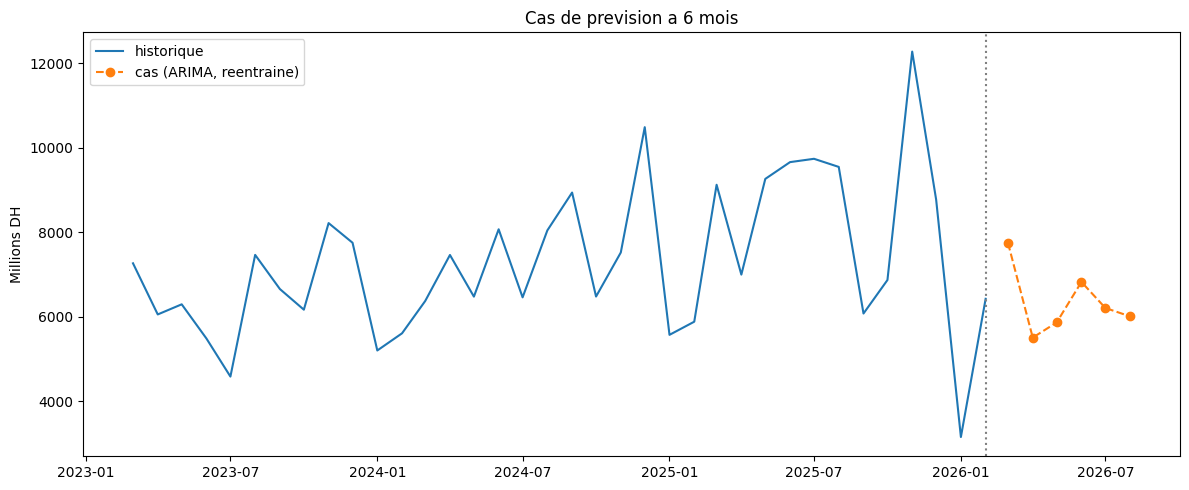

In [30]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index[-36:], df[TARGET].iloc[-36:], label="historique")
ax.plot(forecast.index, forecast.values, label=f"cas ({best_model_name}, reentraine)", linestyle="--", marker="o")
ax.axvline(df.index[-1], color="gray", linestyle=":")
ax.set_title(f"Cas de prevision a {N_FORECAST} mois")
ax.set_ylabel("Millions DH")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Conclusion

Le modele retenu sert au cas de prevision apres reentrainement sur toutes les
donnees. L'evaluation multi-fenetres (5.2) est le resultat a retenir en priorite :
elle montre que la performance depend fortement de la periode testee, ce qu'un score
unique masque. Axes d'amelioration : prevoir reellement les exogenes (prevision
multivariee) plutot que les figer, reevaluer le modele a mesure que de nouvelles
observations arrivent, et surveiller les changements de regime de la serie.